### Sampling initial conditions
Import libraries

In [1]:
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from thermos import *
from sampling_fun import *

Set inputs

In [2]:
# Reading data
path = os.path.abspath(os.getcwd() + f"/../pde/thermolib/strang/output/")
cols = ['rho_O','rho_O2','u','Th','Tv']
# Sampling data
bounds_raw = {
    'XO2': [  0.,      1.],
    'p':   [900., 100000.],
    'Th':  [250.,  10000.],
    'Tv':  [250.,  10000.]
}
nb_train_cases = 5120
nb_test_cases = 50
kde_samples_perc = 0.05
extra_perc = 0.1
# Left/right equilibrium conditions
nb_eq_conds = 2
eq_conds_rep = 20
# Saving path
saving_path = os.path.abspath(os.getcwd() + f"/outputs/sampling/")
if os.path.exists(saving_path):
    shutil.rmtree(saving_path)
os.makedirs(saving_path, exist_ok=True)

Read solution data

In [3]:
data = []
for file in os.listdir(path):
    if file.startswith('restart_EU_NLTE') and file.endswith('_0.dat') and file != 'restart_EU_NLTE_0.dat':
        filename = path + '/' + file
        data.append(np.loadtxt(filename))
        # Get left/right equilibrium conditions
        if file == 'restart_EU_NLTE_0_0.dat':
            data_eq = np.take(np.loadtxt(filename), [1,-1], axis=0)
            df_eq = pd.DataFrame(data_eq, columns=cols)
data = np.vstack(data)
# Create dataframe
df = pd.DataFrame(data, columns=cols)
df_eq = pd.DataFrame(data_eq, columns=cols)

Initialize thermodynamics and extract sampling variables: $X = [X_{O_2}, p, T_h, T_v, T_h-T_v]$

In [4]:
sp_th, mix = init_thermos()

In [5]:
X = extract_sampling_qoi(df, sp_th, mix)
X_eq = extract_sampling_qoi(df_eq, sp_th, mix)[:,:-1]

Set bounds

In [6]:
# Compute bounds
phys_bounds = np.array(list(bounds_raw.values())).T
bounds = compute_bounds(
    X,
    phys_bounds=phys_bounds,
    extra_perc=extra_perc
)

In [7]:
# Force bounds
# Set max dT with (Th_max-Th_min)
bounds[-1,-1] = bounds[1,2] - bounds[0,2]
# Set min Th and Tv
bounds[0,2:4] = bounds_raw['Th'][0]

In [8]:
# Saving computed bounds
df = pd.DataFrame(bounds, columns=list(bounds_raw.keys())+['dT'])
df.index = ['Min', 'Max']
df.to_csv(saving_path + '/bounds.csv', float_format='%.2f')

In [9]:
print('Defined bounds:')
df

Defined bounds:


,XO2,p,Th,Tv,dT
Min,0.7,900.0,250.0,250.0,-80.0
Max,1.0,80000.0,7000.0,5000.0,6600.0


Construct kde

In [10]:
X_ = np.take(X, np.arange(X.shape[1]-1), 1)
scaler = construct_scaler(X_)
kde = construct_kde(X_, bandwidth=0.05, scaler=scaler)

Uniform and kde-based sampling

In [11]:
# nb_samples = {
#     'train': nb_train_cases,
#     'valid': nb_train_cases,
#     'test': nb_test_cases
# }
# sampled_data = {k: [] for k in nb_samples.keys()}
# bounds_prim = np.take(
#     bounds, np.arange(bounds.shape[1]-1), axis=1
# )

# for k, nb in nb_samples.items():
#     while nb > 0:
#         samples = lhs_kde_combined_sampling(
#             nb,
#             bounds,
#             bounds_raw,
#             bounds_prim,
#             kde,
#             scaler,
#             kde_samples_perc
#         )
#         sampled_data[k].append(samples)
#         # Check 'test' data
#         if k == 'test':
#             samples = []
#             for sample in sampled_data['test'][-1]:
#                 cond = np.isclose(sample, sampled_data['train'], rtol=1e-03, atol=1e-05)
#                 cond = np.product(cond, axis=1)
#                 if not any(cond):
#                     samples.append(sample)
#             samples = np.vstack(samples)
#             sampled_data['test'][-1] = samples
#             nb = nb - len(samples)
#         else:
#             nb = 0
#     # Concatenate
#     if len(sampled_data[k]) > 1:
#         sampled_data[k] = np.vstack(sampled_data[k])
#     else:
#         sampled_data[k] = sampled_data[k][-1]

In [12]:
nb_samples = {
    'train': nb_train_cases - eq_conds_rep * nb_eq_conds,
    'valid': nb_train_cases - eq_conds_rep * nb_eq_conds,
    'test': nb_test_cases - nb_eq_conds
}
bounds_prim = np.take(
    bounds, np.arange(bounds.shape[1]-1), axis=1
)

sampled_data = {
    k: lhs_kde_combined_sampling(
        nb,
        bounds,
        bounds_raw,
        bounds_prim,
        kde,
        scaler,
        kde_samples_perc
    ) for k, nb in nb_samples.items()
}


In [13]:
# Add samples for left/right equilibrium conditions
sampled_data['test'] = np.vstack([sampled_data['test'], X_eq])
samples_eq = np.tile(X_eq, (eq_conds_rep,1))
for k in ('train', 'valid'):
    sampled_data[k] = np.vstack([sampled_data[k], samples_eq])

In [14]:
print('Data shapes:')
tf.nest.map_structure(lambda x: x.shape, sampled_data)

Data shapes:


{'train': (5120, 4), 'valid': (5120, 4), 'test': (50, 4)}

Save samples in files

In [15]:
# # Getting indices
# # Testing samples
# indices = np.arange(len(samples))
# np.random.shuffle(indices)
# idx_test = np.random.choice(indices, size=nb_test_cases, replace=False)
# # Training samples
# idx_train = np.setdiff1d(np.arange(len(samples)), idx_test)
# assert np.intersect1d(idx_test, idx_train).size == 0
# # Testing samples for checking training
# idx_testing_train = np.random.choice(idx_train, size=nb_test_cases, replace=False)
# idx_test = np.concatenate([idx_test, idx_testing_train])

In [16]:
# # Saving
# # Testing samples
# for (k, idx) in (('test', idx_test), ('train_valid', idx_train)):
#     df = pd.DataFrame(samples[idx], columns=list(bounds_raw.keys()))
#     path_samples = saving_path + f'/data/{k}/'
#     os.makedirs(path_samples, exist_ok=True)
#     df.to_csv(path_samples + '/inp_space.csv', float_format='%.8e', index=False)

In [17]:
# Saving
# Testing samples
for k, samples in sampled_data.items():
    df = pd.DataFrame(samples, columns=list(bounds_raw.keys()))
    path_samples = saving_path + f'/data/{k}/'
    os.makedirs(path_samples, exist_ok=True)
    df.to_csv(path_samples + '/inp_space.csv', float_format='%.8e', index=False)

Visualize samples

In [18]:
# path_figs = saving_path + '/figs/'
# os.makedirs(path_figs, exist_ok=True)

# labels = ["$T_v$ [K]", "$T_h$ [K]"]
# Th, Tv = samples[:,2], samples[:,3]

# plot_hist_3d(Tv, Th, labels, figname=path_figs+'/hist_3d.pdf', nb_bins=40, show=False)
# plot_hist_2d(Th, Tv, np.flip(labels), figname=path_figs+'/hist_2d.pdf', nb_bins=40, show=False)

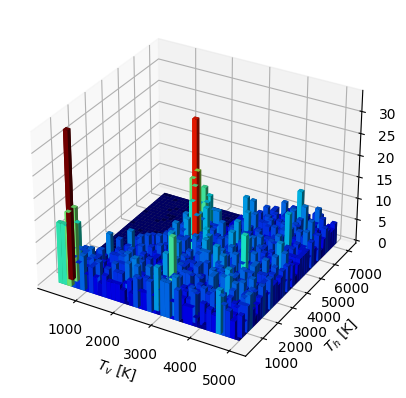

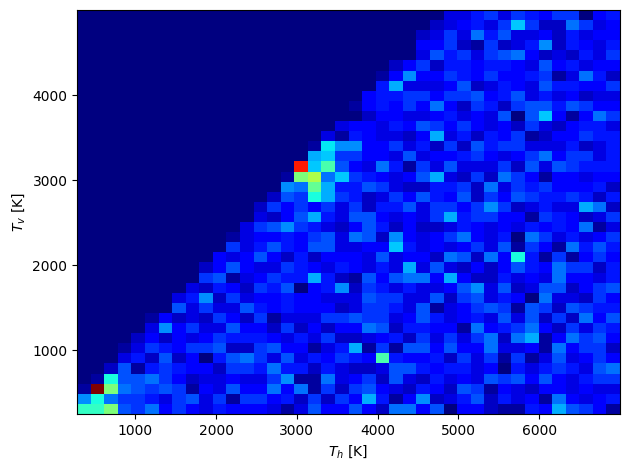

In [19]:
path_figs = saving_path + '/figs/'
os.makedirs(path_figs, exist_ok=True)

labels = ["$T_v$ [K]", "$T_h$ [K]"]
Th, Tv = sampled_data['train'][:,2], sampled_data['train'][:,3]

plot_hist_3d(Tv, Th, labels, figname=path_figs+'/hist_3d.pdf', nb_bins=40, show=1)
plot_hist_2d(Th, Tv, np.flip(labels), figname=path_figs+'/hist_2d.pdf', nb_bins=40, show=1)

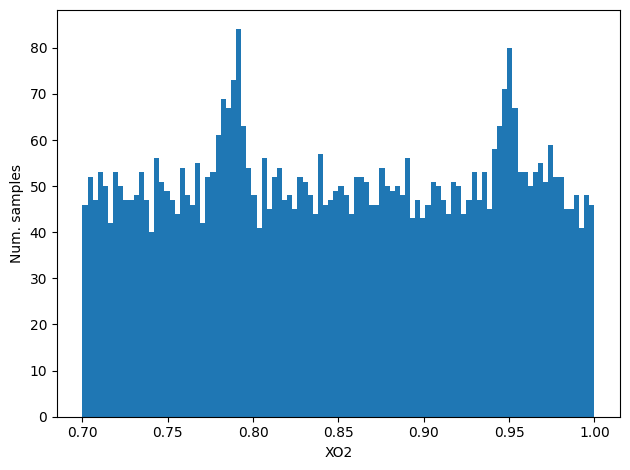

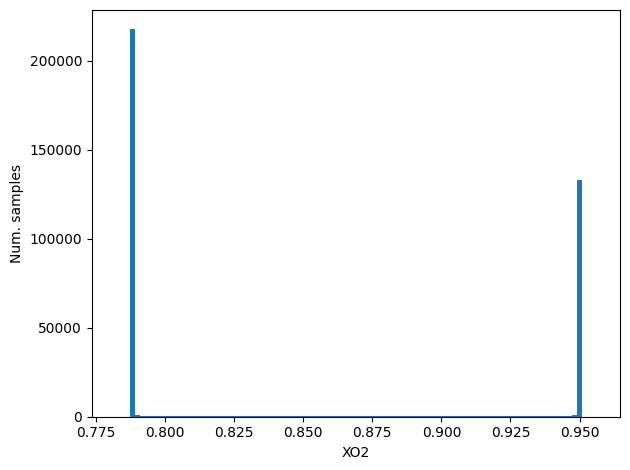

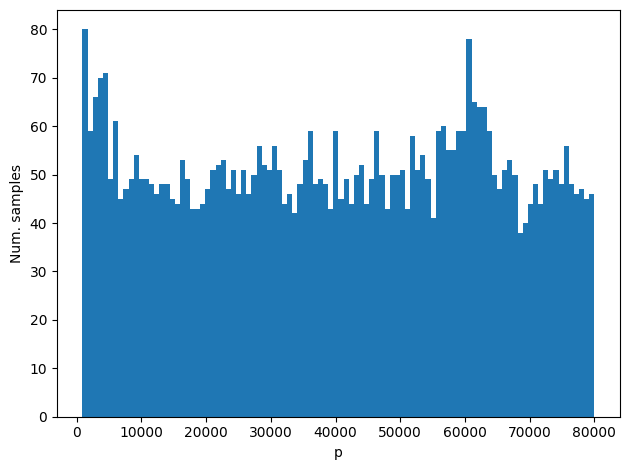

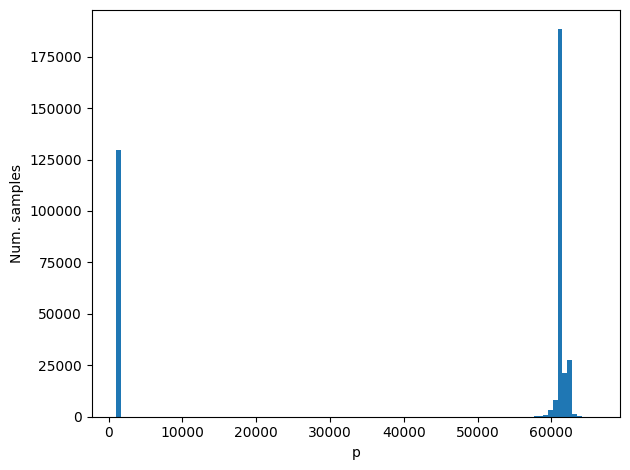

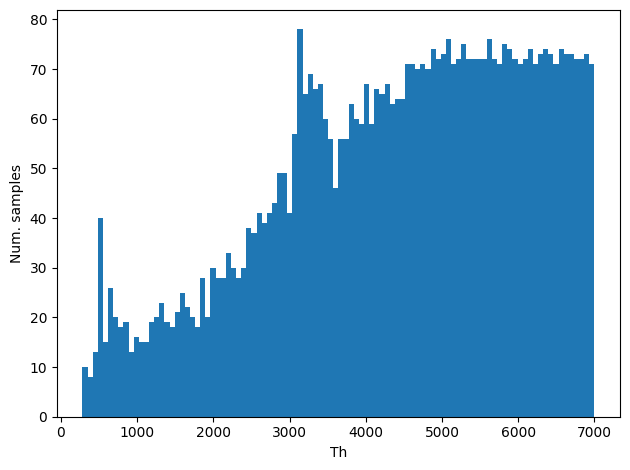

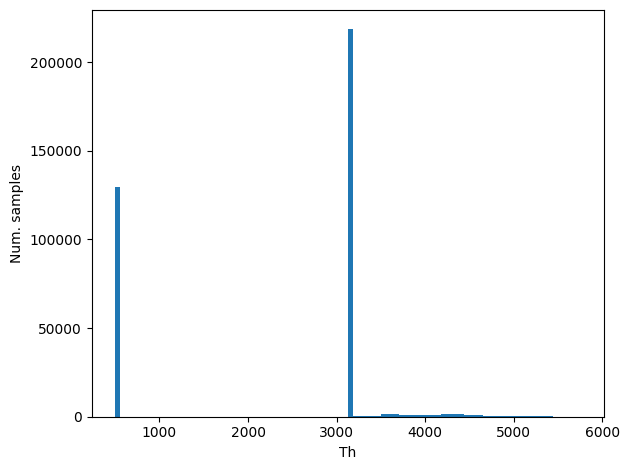

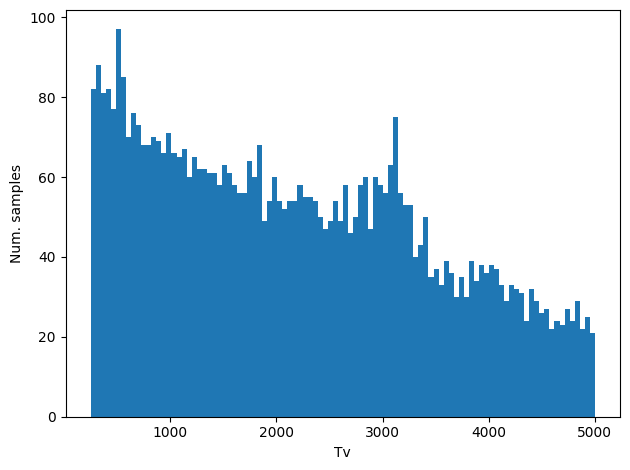

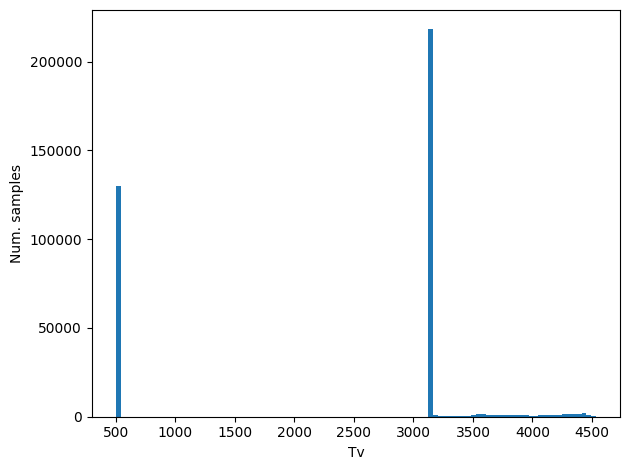

In [20]:
for i, k in enumerate(bounds_raw.keys()):
    plot_hist_1d(sampled_data['train'][:,i], k, figname=path_figs+'/hist_1d_{k}_kde.pdf', nb_bins=100, show=1)
    plot_hist_1d(X[:,i], k, figname=path_figs+'/hist_1d_{k}_data.pdf', nb_bins=100, show=1)